# Sistema inteligente de monitorización y diagnóstico industrial

**Programación de Inteligencia Artificial** · Práctica evaluable

Este cuaderno recorre la práctica paso a paso, explicando cada decisión.
**No contiene la lógica**: importa las funciones de `src/`, que es el mismo código que ejecuta `main.py`
(el entregable oficial). Así el cálculo existe en un único sitio y el cuaderno solo lo narra.

| Pieza | Papel |
| --- | --- |
| `src/` | Toda la lógica, un módulo por fase |
| `main.py` | Ejecuta la práctica completa de principio a fin (entregable) |
| Este cuaderno | Explica y muestra cada paso, con los gráficos en línea |

In [1]:
from pathlib import Path

import numpy as np
from IPython.display import Image, display

from src import analisis, carga, graficos, limpieza

RUTA_DATOS = Path("datos") / "sensores.csv"
RUTA_GRAFICOS = Path("resultados") / "graficos"
np.set_printoptions(suppress=True, precision=3, linewidth=120)

## Apartado 1 · Carga y exploración

**Objetivo:** cargar el CSV en arrays de NumPy, comprobar que es correcto y conocer su estructura.

**Decisiones clave:**
- `np.genfromtxt` en lugar de `np.loadtxt`: convierte cada celda vacía en `np.nan`, así los ausentes quedan marcados dentro del array. `loadtxt` falla con una celda vacía.
- Tres arrays según su papel: `ids` (texto), `mediciones` (matriz `float` de 4 columnas, la X) y `estados` (enteros, la y). Un array de NumPy tiene un solo tipo; mezclar texto y números obligaría a usar `dtype=object` y se perdería la vectorización.
- El `estado` se lee como `float` y después se convierte a `int`: con `dtype=int`, una celda vacía se convertiría en −1 sin ningún aviso.

In [2]:
datos = carga.cargar_datos(RUTA_DATOS)

print("ids       ", datos.ids.shape, datos.ids.dtype)
print("mediciones", datos.mediciones.shape, datos.mediciones.dtype)
print("estados   ", datos.estados.shape, datos.estados.dtype)

ids        (750,) <U5
mediciones (750, 4) float64
estados    (750,) int64


In [3]:
carga.mostrar_resumen(carga.resumen_exploratorio(datos))

Dimensiones: 750 registros x 6 columnas
Variables predictoras: temperatura, vibracion, consumo, presion
Tipos: id=<U5, mediciones=float64, estado=int64

Valores ausentes por variable:
  temperatura    15 (2.0%)
  vibracion      18 (2.4%)
  consumo        19 (2.5%)
  presion        23 (3.1%)
  Registros con al menos un ausente: 73 (9.7%)

Registros por estado:
  0 - Normal                250 (33.3%)
  1 - Desgaste mecánico     250 (33.3%)
  2 - Sobrecalentamiento    250 (33.3%)


In [4]:
carga.mostrar_muestra(datos, n=5)

id       temperatura    vibracion      consumo      presion   estado
S0001         71.423        1.123       25.515        5.431        0
S0002        116.375        2.209       27.219        6.616        2
S0003        -35.000        1.242       16.053        5.107        0
S0004         63.896        4.702       23.308        5.716        1
S0005         83.924        7.018       12.241        4.831        1


### Concepto: `axis`

`axis` indica qué dimensión se **colapsa** al operar:
- `axis=0` colapsa las filas, así que da un resultado **por columna** (por sensor).
- `axis=1` colapsa las columnas, así que da un resultado **por fila** (por registro).

In [5]:
ausentes = np.isnan(datos.mediciones)          # matriz (750, 4) de True/False

print("Huecos por sensor   (axis=0):", ausentes.sum(axis=0))
print("Registros con hueco (axis=1):", ausentes.any(axis=1).sum())

Huecos por sensor   (axis=0): [15 18 19 23]
Registros con hueco (axis=1): 73


**Conclusión:** 750 registros con las clases perfectamente equilibradas (250 por clase), así que el *accuracy* será una métrica fiable.
Hay 75 celdas vacías repartidas en 73 filas (9,7 %): borrarlas todas supondría perder casi un 10 % de los datos.

## Apartado 2 · Limpieza y preparación

**Criterio general:** si un valor es *imposible*, es un error; si es *raro pero posible*, puede ser una anomalía real y se conserva.

| Situación | Tratamiento |
| --- | --- |
| Valor fuera del rango físico | Se convierte en `nan` y se trata como ausente (el resto de la fila es válido) |
| Atípico estadístico dentro del rango | Se conserva y se informa |
| Fila con 2 o más valores por rellenar | Se descarta: la mitad de la fila sería inventada |
| Celda vacía | Se rellena en el apartado 4 con la mediana del **entrenamiento** (sin fuga de datos) |

In [6]:
resultado = limpieza.limpiar(datos)
limpieza.mostrar_resumen_limpieza(datos, resultado)

Valores ausentes en el CSV: 75 celdas en 73 registros

Errores de medición (fuera de rango físico): 11 -> se marcan como ausentes
  S0003  temperatura    -35.00   admisible [0, 150]
  S0037  presion         -3.00   admisible [0, 12]
  S0130  vibracion       -2.50   admisible [0, 15]
  S0149  temperatura    245.00   admisible [0, 150]
  S0168  vibracion       -0.80   admisible [0, 15]
  S0171  vibracion       38.00   admisible [0, 15]
  S0396  temperatura    -18.00   admisible [0, 150]
  S0414  consumo         -1.50   admisible [0, 65]
  S0590  consumo         -4.00   admisible [0, 65]
  S0724  presion         28.00   admisible [0, 12]
  S0728  presion         -1.20   admisible [0, 12]

Decisión por registro:
  Válidos sin cambios:              666
  A corregir (1 valor a imputar):    82
  Descartados (2+ valores):           2  ['S0236', 'S0641']
  Conservados:                      748

Atípicos estadísticos (IQR x1.5) dentro del rango físico -> se CONSERVAN:
  variable      global  por

### ¿Por qué el IQR se calcula dentro de cada clase?

Si el IQR se calcula sobre todo el dataset, se marcan como "atípicas" las vibraciones altas.
Pero una vibración alta es justo la **señal del desgaste**. Veamos de qué clase son esos atípicos:

In [7]:
vibracion_atipica_global = resultado.atipicos_globales[:, 1]
por_estado = [int(vibracion_atipica_global[datos.estados == e].sum()) for e in (0, 1, 2)]
print("Vibraciones atípicas (IQR global) por estado 0/1/2:", por_estado)

Vibraciones atípicas (IQR global) por estado 0/1/2: [0, 14, 4]


La mayoría son de la clase 1 (desgaste): el criterio global trataría como ruido justo el patrón que queremos aprender.
Por eso los atípicos se buscan dentro de cada clase.

In [8]:
datos_limpios = resultado.datos
print("Registros conservados:", len(datos_limpios.ids))
print("Huecos pendientes de imputar (apartado 4):", int(np.isnan(datos_limpios.mediciones).sum()))

Registros conservados: 748
Huecos pendientes de imputar (apartado 4): 82


## Apartado 3 · Análisis estadístico

**Decisiones:**
- Se analizan los datos **limpios sin imputar**, con funciones que ignoran los `nan` (`np.nanmean`, `np.nanpercentile`…): se describen solo valores realmente medidos.
- La desviación estándar es **muestral** (`ddof=1`, corrección de Bessel): los registros son una muestra del comportamiento de las máquinas.
- Para medir qué variable distingue los estados se usan dos medidas: el **estadístico F** (una nota global por variable) y la **d de Cohen** por pareja de clases (qué separa cada variable).

In [9]:
X, y, variables = datos_limpios.mediciones, datos_limpios.estados, datos_limpios.variables

print("Estadísticos globales:")
analisis.mostrar_estadisticos(analisis.calcular_estadisticos(X), variables)

Estadísticos globales:
               temperatura   vibracion     consumo     presion
  media              83.02        3.42       22.55        6.06
  mediana            78.50        3.03       21.76        6.10
  desviacion         19.60        1.72        6.36        1.11
  minimo             41.09        0.05        6.93        1.22
  maximo            143.20       10.51       53.92       10.02
  q1                 67.76        2.15       18.11        5.36
  q3                 97.61        4.35       26.17        6.73
  iqr                29.85        2.20        8.06        1.36


La temperatura global tiene una media de 83,0 y una mediana de 78,5. No hay ningún sensor raro: el grupo de sobrecalentamiento arrastra la media.
Las estadísticas globales mezclan tres poblaciones distintas, así que lo que de verdad sirve es comparar **por clase**:

In [10]:
analisis.mostrar_comparativa_por_clase(*analisis.estadisticos_por_clase(X, y), variables)


  TEMPERATURA
                            Normal   Desgaste mecánico  Sobrecalentamiento
  media                      67.82               76.98              104.33
  mediana                    68.07               77.31              104.82
  desviacion                 10.24               12.27               13.22
  minimo                     41.09               46.44               66.28
  maximo                    131.41              123.26              143.20
  q1                         60.80               67.77               95.94
  q3                         74.32               84.37              112.66
  iqr                        13.52               16.59               16.72

  VIBRACION
                            Normal   Desgaste mecánico  Sobrecalentamiento
  media                       2.07                5.08                3.14
  mediana                     2.10                5.11                3.03
  desviacion                  0.68                1.47                1.

### ¿Qué variable distingue cada estado?

- **F (ANOVA)** = varianza *entre* clases / varianza *dentro* de las clases. Cuanto más alto, mejor separa la variable las tres clases a la vez.
- **d de Cohen** = |media_a − media_b| / desviación conjunta. Mide la distancia entre dos clases en desviaciones estándar; si es mayor que 0,8, la separación es grande.

In [11]:
parejas, d = analisis.d_cohen_por_pareja(X, y)
analisis.mostrar_separabilidad(analisis.ratio_f(X, y), parejas, d, variables)

  Estadístico F (ANOVA), de mayor a menor capacidad de separar las 3 clases:
    temperatura     615.9
    vibracion       400.2
    consumo         233.3
    presion          20.9

  d de Cohen por pareja de estados (> 0.8 = separación grande):
                  0 vs 1    0 vs 2    1 vs 2
  temperatura       0.81      3.09      2.14
  vibracion         2.63      1.05      1.41
  consumo           0.87      1.94      1.10
  presion           0.60      0.45      0.07

  Conclusiones:
    Normal vs Desgaste mecánico: la separa mejor 'vibracion' (d=2.63); variables con separación grande: ['temperatura', 'vibracion', 'consumo']
    Normal vs Sobrecalentamiento: la separa mejor 'temperatura' (d=3.09); variables con separación grande: ['temperatura', 'vibracion', 'consumo']
    Desgaste mecánico vs Sobrecalentamiento: la separa mejor 'temperatura' (d=2.14); variables con separación grande: ['temperatura', 'vibracion', 'consumo']
    Sin separación grande en ninguna pareja: ['presion']


### Gráficos

Se generan con `src/graficos.py`, se guardan en `resultados/graficos/` y se muestran aquí.
Cada estado tiene siempre el mismo color, comprobado para que se distinga también con daltonismo.

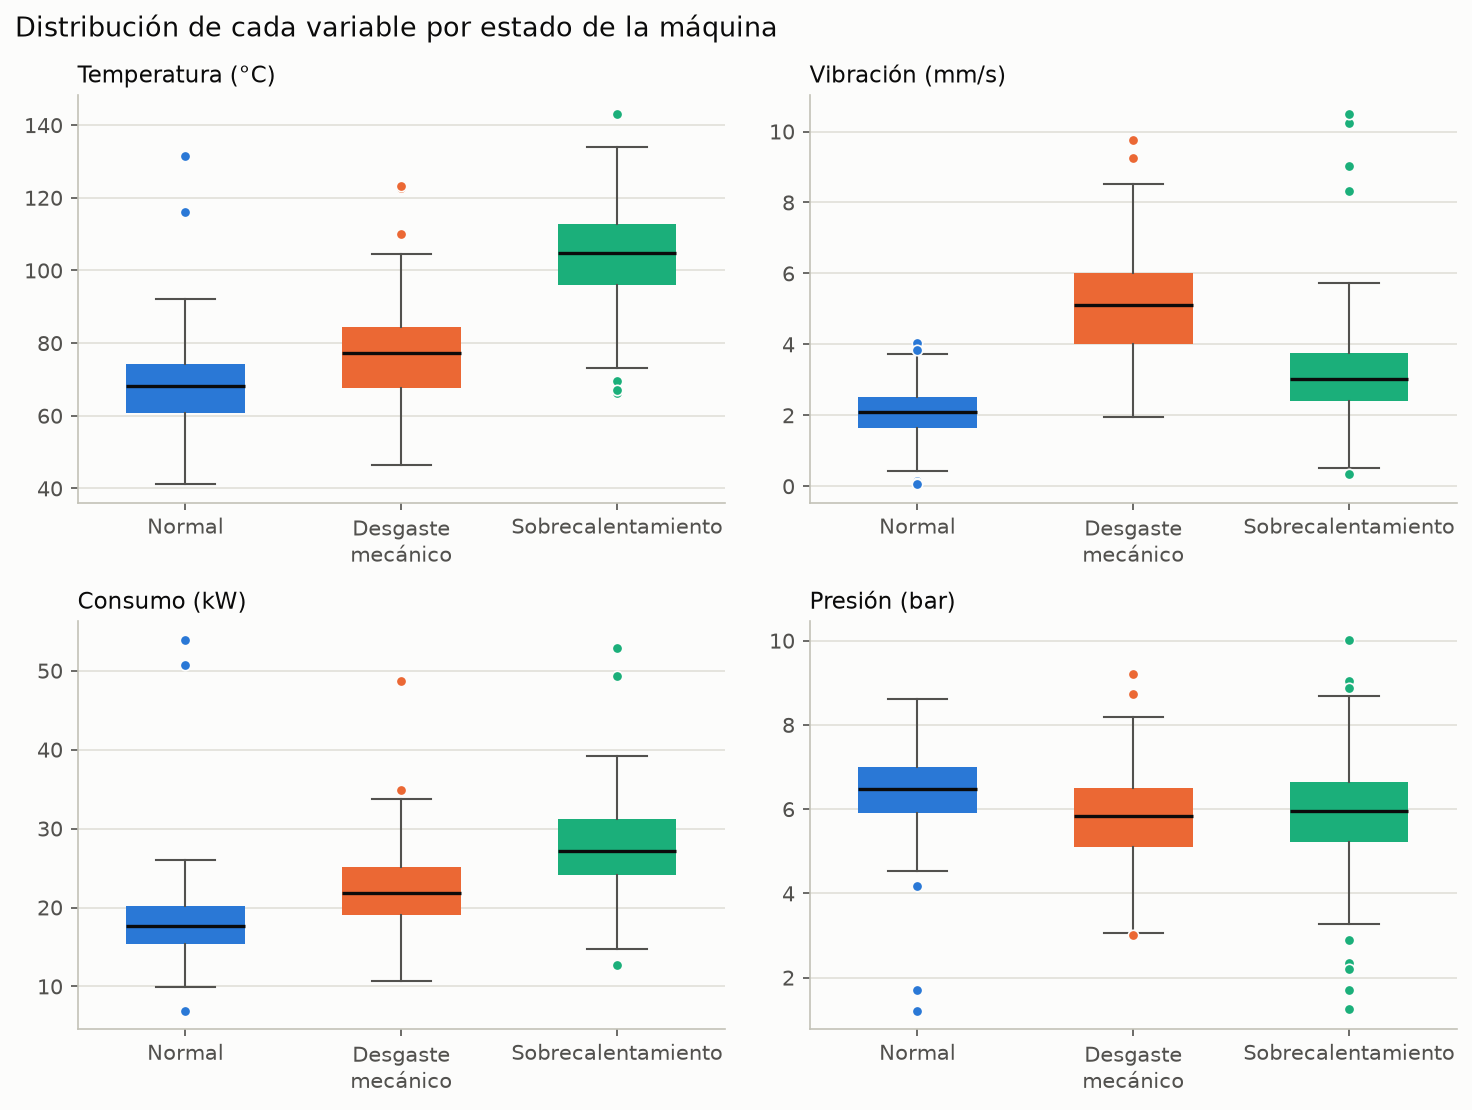

In [12]:
ruta = graficos.boxplots_por_clase(X, y, carga.NOMBRES_LEGIBLES, carga.UNIDADES, RUTA_GRAFICOS)
display(Image(filename=ruta))

**Lectura:** en temperatura, la caja de sobrecalentamiento no se solapa con las otras dos. En vibración, la de desgaste queda por encima de las demás.
En presión, las tres cajas están a la misma altura: no distingue. Los puntos sueltos son los atípicos de cada clase (`whis=1.5`, el mismo criterio que en el apartado 2).

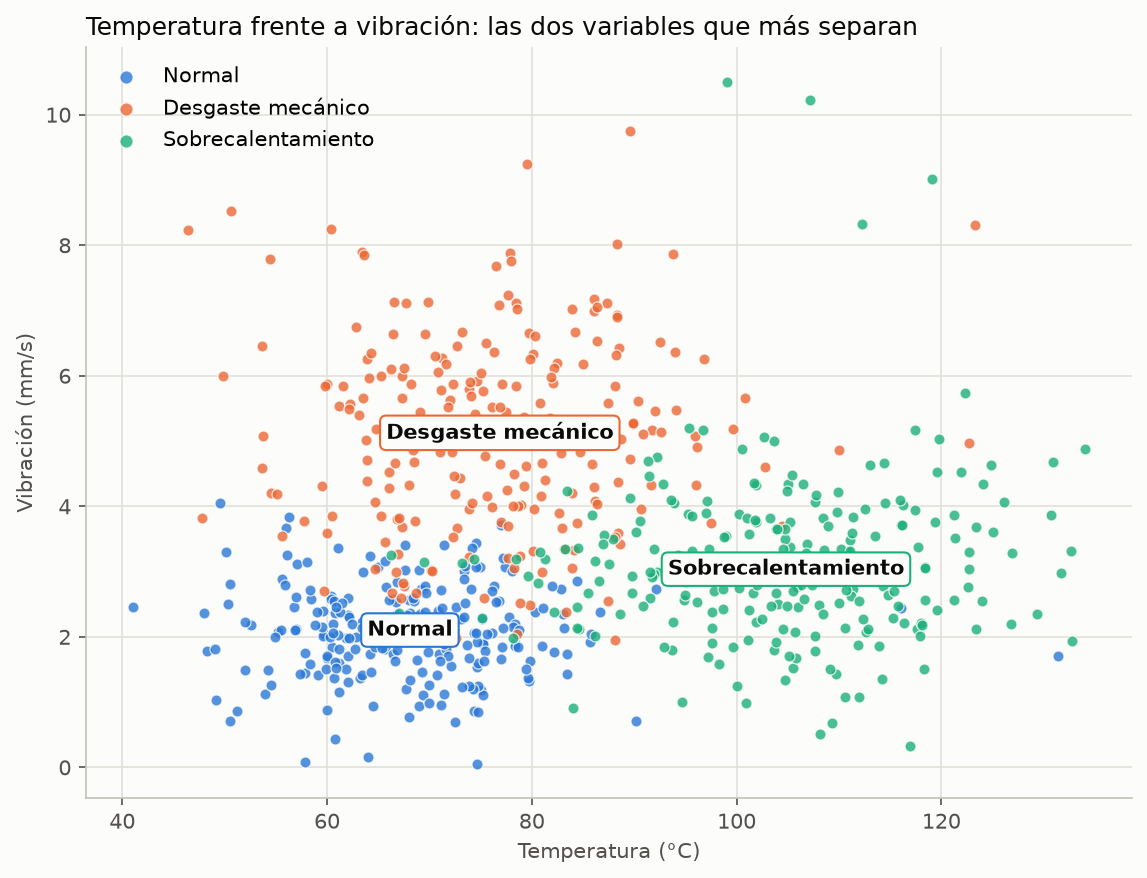

In [13]:
ruta = graficos.dispersion(X, y, carga.NOMBRES_LEGIBLES, carga.UNIDADES, RUTA_GRAFICOS)
display(Image(filename=ruta))

**Lectura:** tres nubes de puntos (normal abajo a la izquierda, desgaste arriba, sobrecalentamiento a la derecha) que se mezclan en la zona de 75–90 °C y 2,5–4 mm/s.
Ahí es donde el clasificador cometerá errores.

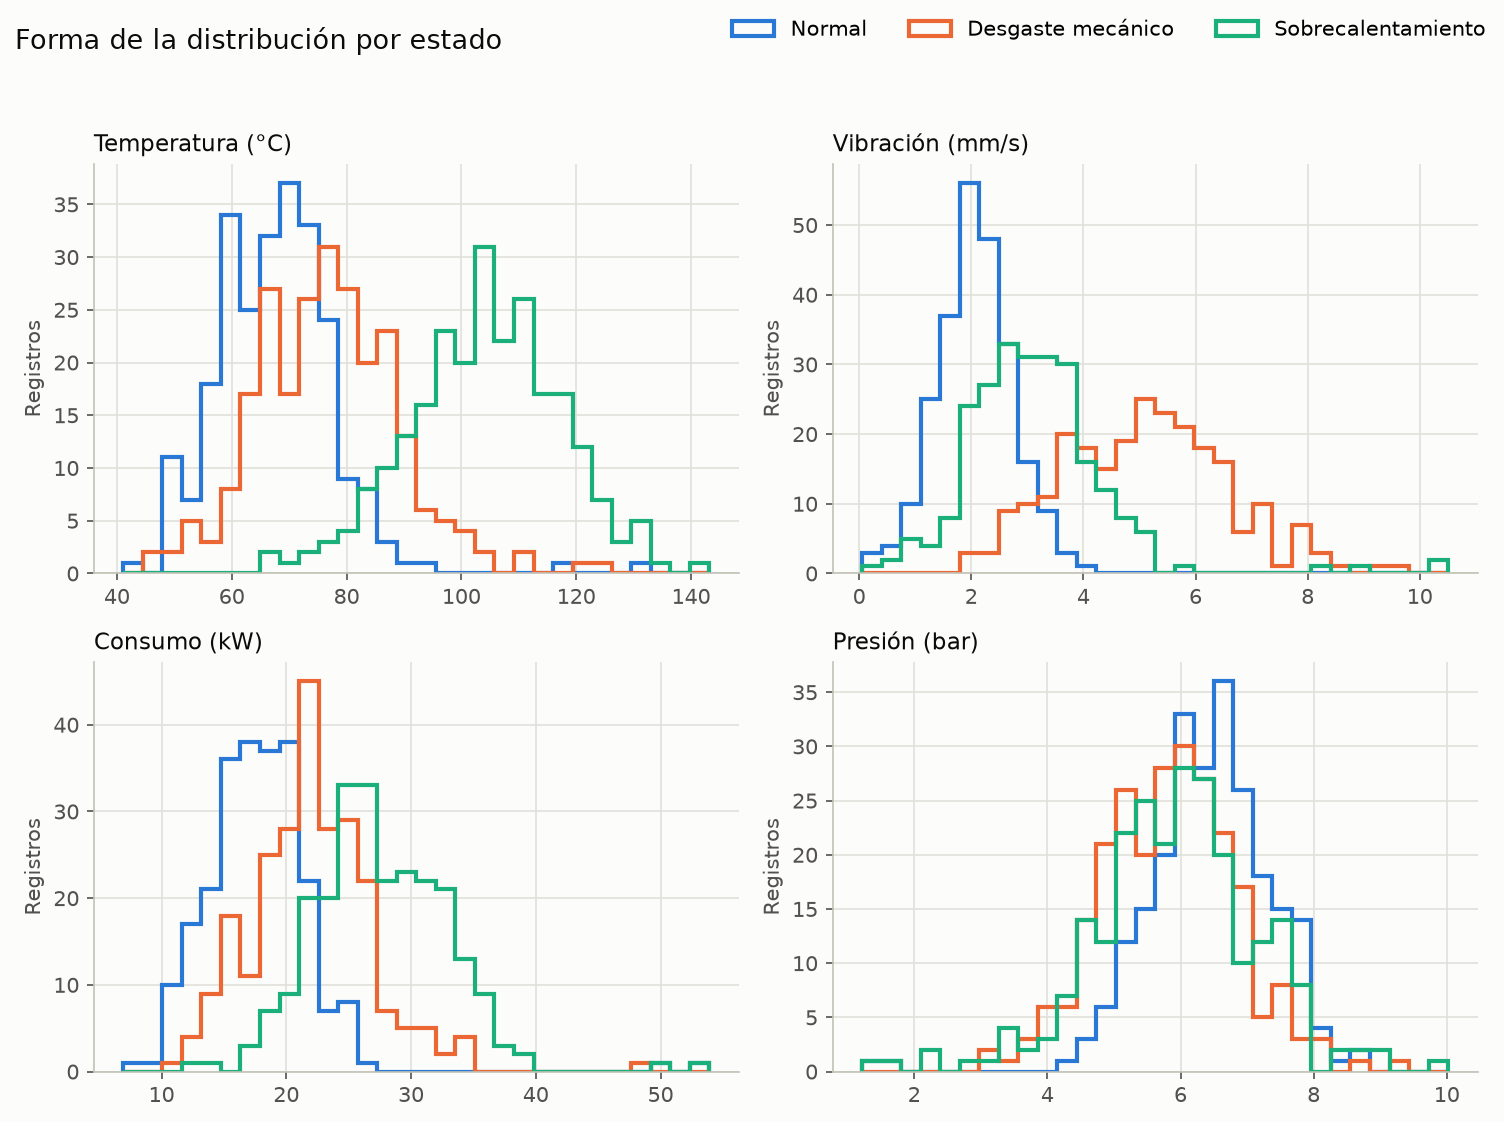

In [14]:
ruta = graficos.histogramas_por_clase(X, y, carga.NOMBRES_LEGIBLES, carga.UNIDADES, RUTA_GRAFICOS)
display(Image(filename=ruta))

**Lectura:** cada clase tiene forma de campana más o menos simétrica, así que la media representa bien a cada clase, y eso es lo que usará el clasificador de centroides.
En presión, las tres curvas se superponen casi por completo.

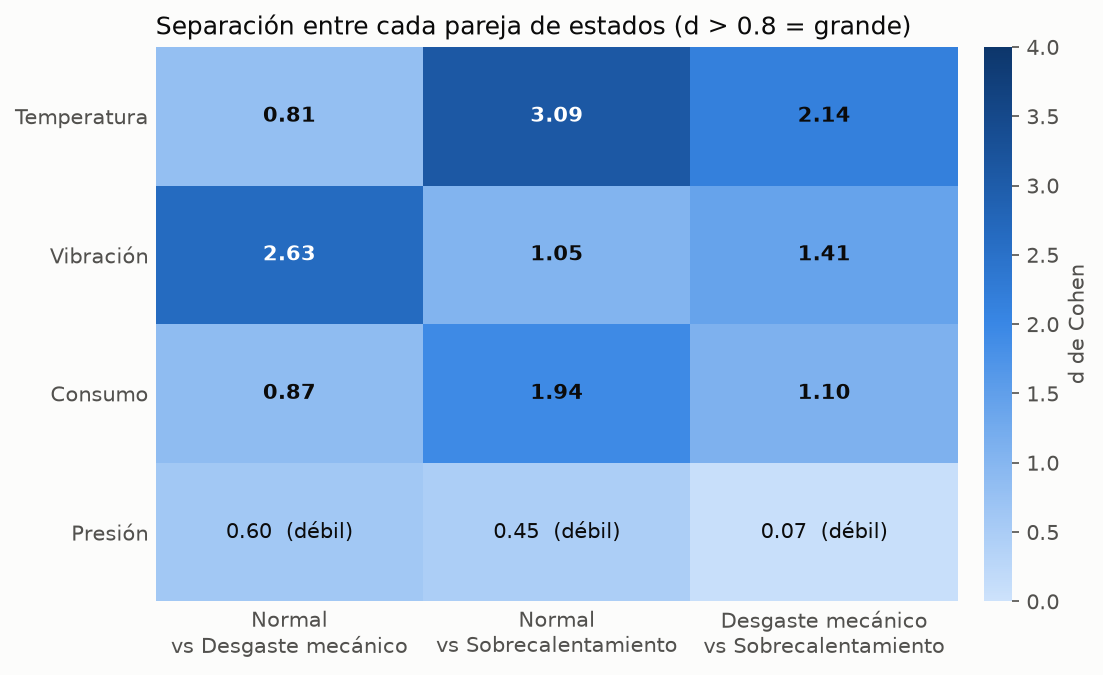

In [15]:
ruta = graficos.mapa_calor_cohen(d, parejas, carga.NOMBRES_LEGIBLES, RUTA_GRAFICOS)
display(Image(filename=ruta))

**Conclusiones del apartado 3:**
1. La **temperatura** separa el sobrecalentamiento y la **vibración** separa el desgaste; el **consumo** ayuda de forma moderada.
2. La **presión** apenas aporta, pero después de normalizar pesará lo mismo que las demás en la distancia euclídea. Es una limitación que hay que señalar.
3. La pareja **normal–desgaste** es la más difícil (solo la vibración las distingue). Se espera que ahí se concentren los errores del apartado 6.